# SYNCEDSTRUCTURE
### **A Class to handle, crossreference and annotate Structural Proteomics Data**

Credits:
LICENCES:

In [1]:
### <DEPENDENCIES and SyncedStructure Methods display> 
import re, urllib.request, io, copy
import pickle
import pandas as pd
import seaborn as sns
from synced_structure import SyncedStructure
from viz3d import side_by_side

def get_uniprot(uid):
    u = str(uid).strip().upper()
    if not re.match(r"^([OPQ][0-9][A-Z0-9]{3}[0-9]|[A-NR-Z][0-9]([A-Z][A-Z0-9]{2}[0-9]){1,2})(-\d+)?$", u):
        raise ValueError()
    buf = io.StringIO(urllib.request.urlopen(f"https://rest.uniprot.org/uniprotkb/{u}.fasta").read().decode())
    return u, "".join(buf.read().splitlines()[1:])


pd.set_option("display.width", 1000)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_rows", 100)

synced_structure_options = dir(SyncedStructure)
d = [x for x in synced_structure_options if x.startswith("__")]
h = [x for x in synced_structure_options
    if x.startswith("_") and not x.startswith("__")]
e = [x for x in synced_structure_options if not x.startswith("_")]
for g in (d, h, e):
  if g:
    [print(g[i : i + 4]) for i in range(0, len(g), 4)]
    print()
### <\DEPENDENCIES and SyncedStructure Methods display>

['__class__', '__contains__', '__delattr__', '__dict__']
['__dir__', '__doc__', '__eq__', '__firstlineno__']
['__format__', '__ge__', '__getattribute__', '__getitem__']
['__getstate__', '__gt__', '__hash__', '__init__']
['__init_subclass__', '__iter__', '__le__', '__len__']
['__lt__', '__module__', '__ne__', '__new__']
['__reduce__', '__reduce_ex__', '__repr__', '__setattr__']
['__sizeof__', '__static_attributes__', '__str__', '__subclasshook__']
['__weakref__']

['_apply_chain_options', '_atom_contacts', '_atom_pair_maps', '_auth_of']
['_block_entries', '_build_chains', '_ca_records', '_chain_colors']
['_chain_description_map', '_chain_entity_map', '_checked_matrix', '_clean_val']
['_compute_interface', '_compute_local_alignment', '_draw_pair', '_entity_sequences']
['_external_refs_for_entity', '_gray_matrix', '_heavy_atoms', '_hydrophobicity']
['_interactive_view', '_keep_mapped', '_label_of', '_local_alignment']
['_make_ca_trajectory', '_make_chain_data', '_make_sidechain_trajectory

## Human Replisome bound to DNA Pol Alpha (8B9D)

Deposited in **RCSB on [October 2022](https://www.rcsb.org/structure/8B9D)**

In a previous tutorial, `Tutorial-Create.ipynb` we selected a Protein-Protein interface subset and saved it to `tutorial-data`.\
Conveniently, we will use the same naming convention and refer to that as `sync_ntd`, aka a `SyncedStructure` class object containing `TIM` (author chain K). This structure maps to the N-most part of the protein sequence.

In [2]:
### <Interface LOADING> 

INTERFACE_PATH="tutorial-data/TIM-interface.pkl"
with open(INTERFACE_PATH, "rb") as f:
    sync_ntd = pickle.load(f)
sync_ntd.rename_chains({'2':'A', '6':'B'})
print(sync_ntd.summary())
### <\PDB ID LOADING>

  chain_id auth_chain_id entity_id                            description external_ref  sequence_length  reference_length  mapped_residues  mapping_fraction
0        M             K        13               Protein timeless homolog       Q9UNS1              638              1208              638               1.0
1        O             M        15                     Leading strand DNA         None                0                84                0               0.0
2        P             N        16                           DNA Molecule         8B9D                0                86                0               0.0
3        A             A         1  DNA replication licensing factor MCM2       P49736              576               904              576               1.0
4        E             B         5  DNA replication licensing factor MCM6       Q14566              607               821              607               1.0


In [3]:
sync_ntd.jupy_viz(title="Timeless interface with DNA and Replisome")

[PYTHON-INFO] 2026-10-16 14:38:02 | Rendered interactive view of 8B9D at angles (0, 0, 0) | execution time: 1.76s | max memory: 418.8 MB


### Contact Calculation and Summarization

Here we will obtain contacts between and within chains.
Specifically, We are interested in K's contacts with all other protein chains
We also plan to compute K's contacts with DNA molecules (author ids 'M' and 'N')

```
compute_contacts(
    self,
    cutoff=0.8,
    contact_type='inter',
    chain_ids=None,
    scheme='ca'
)
    Return a DataFrame of residue pairs closer than the cutoff in nm.
    Args:
        cutoff: Distance cutoff in nm.
        contact_type: 'inter', 'intra', or 'all'.
        chain_ids: Chains to include, or None for all.
        scheme: mdtraj contact scheme. Supported: 'ca' (default, C-alpha only)
                and 'sidechain'. Other mdtraj schemes may work if a full-atom
                trajectory is available.
```



In [4]:
caca_contacts = sync_ntd.compute_contacts(cutoff=0.8, scheme="ca")
print(f"Found {len(caca_contacts)} inter-chain Ca-Ca contacts")
print(caca_contacts.head())
print()

#side_contacts = sync_ntd.compute_contacts(cutoff=0.5, scheme="sidechain")
#print(f"Found {len(side_contacts)} inter-chain R-R contacts")
#print(side_contacts.head())
#print()


Found 158 inter-chain Ca-Ca contacts
  chain_1 auth_chain_1  resnum_1 resname_1  sequence_index_1 chain_2 auth_chain_2  resnum_2 resname_2  sequence_index_2  min_distance_nm contact_type moiety_1 moiety_2
0       M            K         8       CYS                 1       A            A       188       MET                15           0.7271        inter  protein  protein
1       M            K         8       CYS                 1       A            A       189       ALA                16           0.7359        inter  protein  protein
2       M            K        12       ALA                 5       A            A       190       GLY                17           0.7322        inter  protein  protein
3       M            K        58       ALA                51       A            A       179       GLY                 6           0.7426        inter  protein  protein
4       M            K        59       GLN                52       A            A       179       GLY                 6    

(<Figure size 450x450 with 1 Axes>,
 <Axes: title={'center': 'Contacts M-M (cutoff 0.8 nm)'}, xlabel='Chain M', ylabel='Chain M'>)

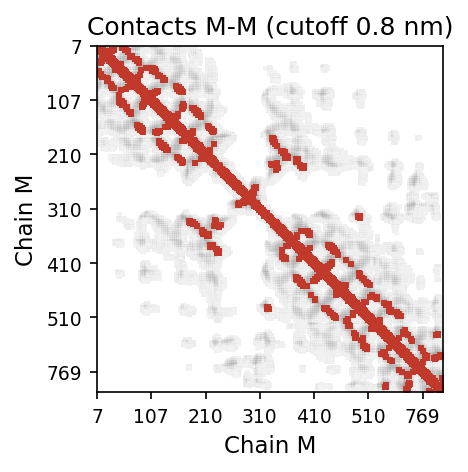

In [18]:
sync_ntd.plot_contact_map("K", cutoff=0.8, gray_cutoff=3, size_in=3, tick_step=100)

(<Figure size 600x600 with 2 Axes>,
 <Axes: title={'center': 'Contacts M and E (cutoff 0.8 nm)'}, xlabel='Chain M | Chain E', ylabel='Chain M | Chain E'>)

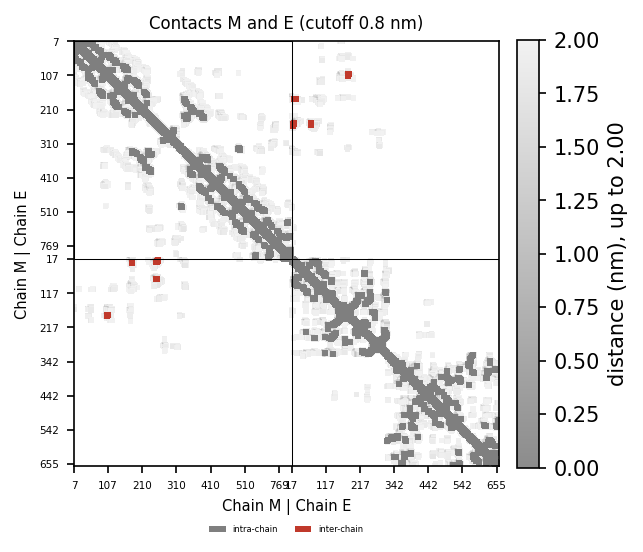

In [9]:
sync_ntd.plot_contacts_two("K", "B", cutoff=0.8, gray_cutoff=2, tick_step=100, size_in=4, font_size=7)
